# 01 – Exploratory Data Analysis
UCI Heart Disease (Cleveland): 303 patients, 13 features. Target: heart disease yes/no.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/heart.csv")
df["target"] = (df["num"] > 0).astype(int)   # 1 = disease, 0 = no disease
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


In [2]:
df.info()
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
 14  target    303 non-null    int64  
dtypes: float64(13), int64(2)
memory usage: 35.6 KB

Missing values:
 ca      4
thal    2
dtype: int64


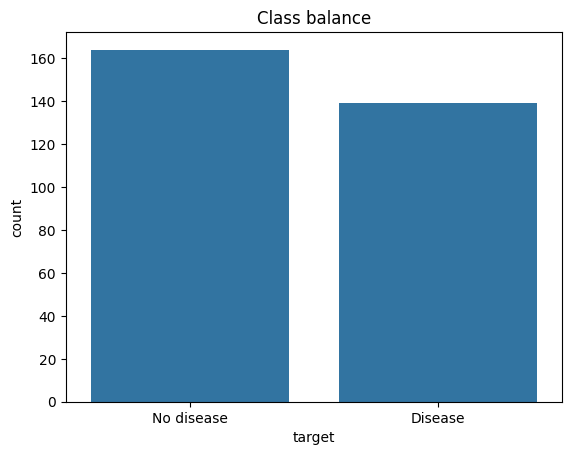

target
0    164
1    139
Name: count, dtype: int64

In [3]:
sns.countplot(data=df, x="target")
plt.xticks([0, 1], ["No disease", "Disease"])
plt.title("Class balance")
plt.show()
df["target"].value_counts()

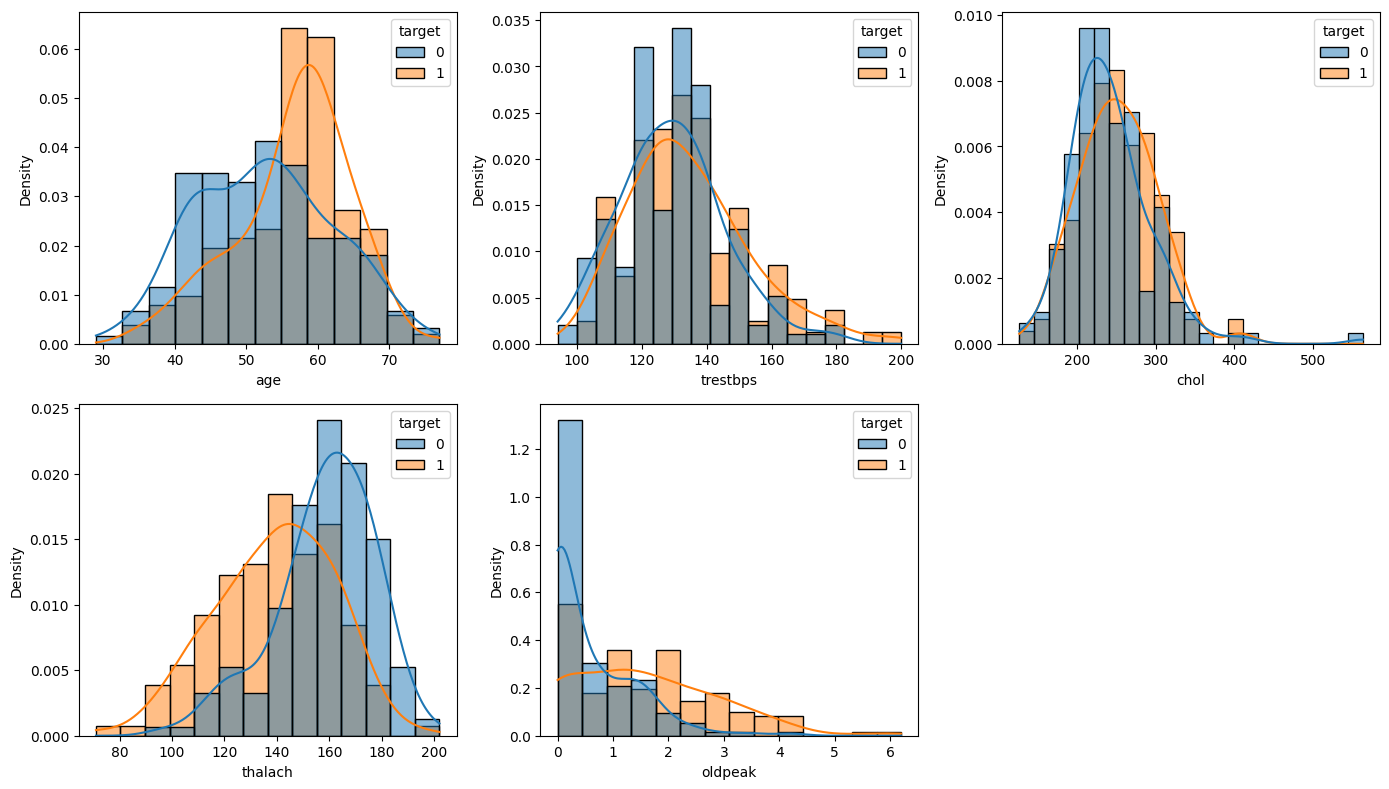

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, ["age", "trestbps", "chol", "thalach", "oldpeak"]):
    sns.histplot(data=df, x=col, hue="target", kde=True, stat="density", common_norm=False, ax=ax)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

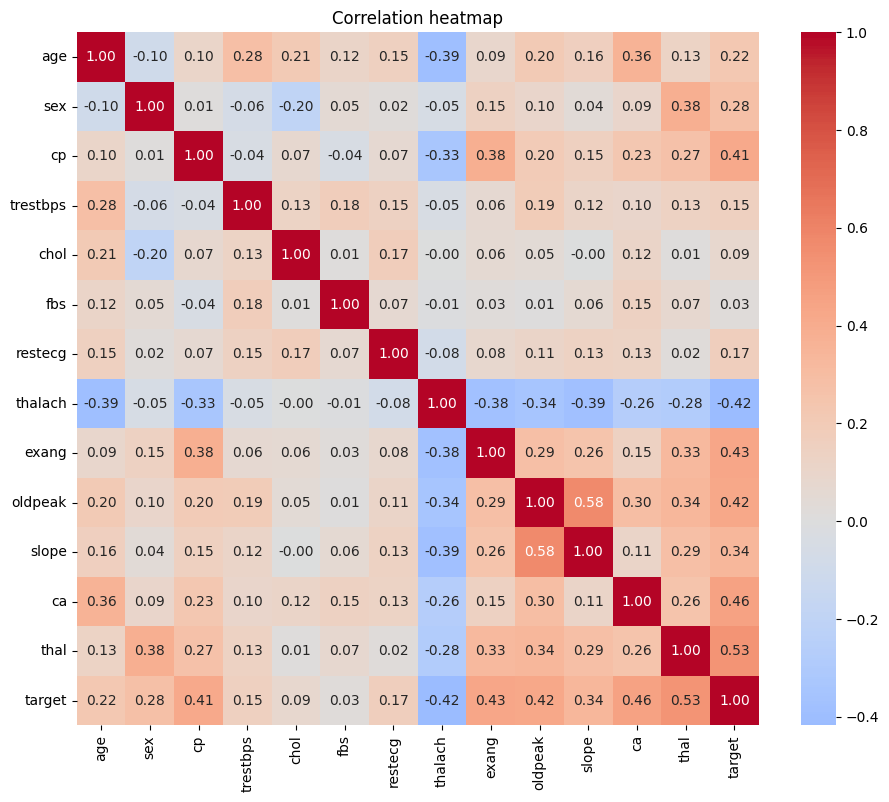

target      1.000000
thal        0.525689
ca          0.460442
exang       0.431894
oldpeak     0.424510
cp          0.414446
slope       0.339213
sex         0.276816
age         0.223120
restecg     0.169202
trestbps    0.150825
chol        0.085164
fbs         0.025264
thalach    -0.417167
Name: target, dtype: float64

In [5]:
plt.figure(figsize=(11, 9))
sns.heatmap(df.drop(columns="num").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()
df.drop(columns="num").corr()["target"].sort_values(ascending=False)

## Observations

- **Dataset:** 303 patients, 13 features. Only 6 missing values (`ca`: 4, `thal`: 2), so we will fill them in (impute) instead of dropping rows.
- **Class balance:** 164 without disease vs 139 with disease (54% / 46%). The data is roughly balanced, so no special balancing is needed, but we will use stratified train/test splits.
- **Strongest signals:** `thal` (0.53), `ca` (0.46), `exang` (0.43), `oldpeak` (0.42) and `cp` (0.41) have the highest positive correlation with disease. `thalach` (max heart rate) has a strong negative correlation (-0.42): patients with disease reach a lower maximum heart rate.
- **Weak signals:** `chol` (0.09) and `fbs` (0.03) barely differ between the two groups.
- **Distributions:** patients with disease tend to be older (peak around 58-60) and show higher ST depression (`oldpeak`).
- **Outliers:** one cholesterol value is around 564, much higher than the rest. It is a plausible value, so we keep it; scaling will reduce its effect.
- **Feature types:** `cp`, `thal`, `restecg` and `slope` are category codes, not quantities, so they will be one-hot encoded. Numeric features (age, blood pressure, cholesterol, heart rate, oldpeak) will be scaled.